# PRML Lab 1 — Python, NumPy, Pandas, Plotting & Evaluation Metrics
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import os
import subprocess
from collections import Counter
from datetime import datetime
from itertools import chain

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = 'data'
np.random.seed(56)

## Problem 1 — Basics of Python

**(a) Convert file data to a list** — one element per line, trailing newlines stripped.

In [2]:
with open(os.path.join(DATA, 'file.txt')) as f:
    lines = [line.rstrip('\n') for line in f]
lines

['Hello, this is Aryan Tiwari (B20AI056).',
 'This file is read line by line and converted into a list.',
 'PRML Lab 1 - Winter 2022']

**(b) Convert user input to a number.** `input()` always returns a string, so it has to be cast. The helper tries `int` first and falls back to `float`; the notebook feeds it fixed strings so it runs non-interactively.

In [3]:
def to_number(text):
    text = text.strip()
    try:
        return int(text)
    except ValueError:
        return float(text)

# raw = input('Enter a number: ')
for raw in ['56', '3.14', ' -7 ']:
    value = to_number(raw)
    print(repr(raw), '->', value, type(value).__name__)

'56' -> 56 int
'3.14' -> 3.14 float
' -7 ' -> -7 int


**(c) Convert a string to a datetime** with `datetime.strptime` and an explicit format.

In [4]:
deadline = datetime.strptime('23-01-2022 18:00', '%d-%m-%Y %H:%M')
print(deadline, '| weekday:', deadline.strftime('%A'))

2022-01-23 18:00:00 | weekday: Sunday


**(d) Call external commands.** `subprocess.run` is the recommended way (safer than `os.system`, and it captures output).

In [5]:
result = subprocess.run(['echo', 'Hello from the shell'], capture_output=True, text=True)
print('return code:', result.returncode)
print('stdout:', result.stdout.strip())

return code: 0
stdout: Hello from the shell


**(e) Count occurrences of a list item.**

In [6]:
grades = ['A', 'B', 'A', 'C', 'B', 'A', 'A-']
print("count('A') =", grades.count('A'))
print('all counts  =', Counter(grades))

count('A') = 3
all counts  = Counter({'A': 3, 'B': 2, 'C': 1, 'A-': 1})


**(f) Flatten a list of lists** — comprehension, `itertools.chain`, and a recursive version for arbitrary nesting.

In [7]:
nested = [[1, 2], [3, 4, 5], [6]]
print([x for sub in nested for x in sub])
print(list(chain.from_iterable(nested)))

def flatten(items):
    for item in items:
        if isinstance(item, (list, tuple)):
            yield from flatten(item)
        else:
            yield item

print(list(flatten([1, [2, [3, [4, 5]]], 6])))

[1, 2, 3, 4, 5, 6]
[1, 2, 3, 4, 5, 6]
[1, 2, 3, 4, 5, 6]


**(g) Merge dictionaries.** With duplicate keys the right-hand dictionary wins.

In [8]:
d1 = {'name': 'Aryan', 'branch': 'AI'}
d2 = {'roll': 'B20AI056', 'branch': 'AIDS'}
print({**d1, **d2})
merged = d1.copy(); merged.update(d2)
print(merged)

{'name': 'Aryan', 'branch': 'AIDS', 'roll': 'B20AI056'}
{'name': 'Aryan', 'branch': 'AIDS', 'roll': 'B20AI056'}


**(h) Remove duplicates from a list** — `set()` loses order; `dict.fromkeys` keeps first-seen order.

In [9]:
values = [3, 1, 3, 2, 1, 5, 2]
print(list(set(values)))
print(list(dict.fromkeys(values)))

[1, 2, 3, 5]
[3, 1, 2, 5]


**(i) Check whether a key already exists in a dictionary.**

In [10]:
def key_exists(d, key):
    return key in d

student = {'name': 'Aryan', 'roll': 'B20AI056', 'cgpa': None}
for k in ['roll', 'email', 'cgpa']:
    print(f'{k!r:8} exists: {key_exists(student, k)}')

'roll'   exists: True
'email'  exists: False
'cgpa'   exists: True


## Problem 2 — NumPy

In [11]:
A = np.random.randint(1, 10, size=(3, 3))
B = np.random.randint(1, 10, size=(3, 3))
print('A =\n', A, '\nB =\n', B)

A =
 [[6 5 1]
 [3 8 7]
 [5 8 2]] 
B =
 [[9 3 1]
 [6 7 2]
 [6 6 3]]


In [12]:
print('(a) first row of A      :', A[0])
print('(b) second column of B   :', B[:, 1])
print('(c) matrix product A @ B :\n', A @ B)
print('(d) element-wise A * B   :\n', A * B)

(a) first row of A      : [6 5 1]
(b) second column of B   : [3 7 6]
(c) matrix product A @ B :
 [[ 90  59  19]
 [117 107  40]
 [105  83  27]]
(d) element-wise A * B   :
 [[54 15  1]
 [18 56 14]
 [30 48  6]]


**(e) Dot product between each column of A and each column of B.** Entry *(i, j)* is `A[:, i] · B[:, j]`, which is exactly `Aᵀ B`; checked against an explicit loop.

In [13]:
col_dots = A.T @ B
loop = np.array([[A[:, i] @ B[:, j] for j in range(B.shape[1])] for i in range(A.shape[1])])
print(col_dots)
print('matches loop:', np.array_equal(col_dots, loop))

[[102  69  27]
 [141 119  45]
 [ 63  64  21]]
matches loop: True


## Problem 3 — Pandas (Cars93)

Pandas treats the string `None` as missing by default, but in the **AirBags** column `None` is a real category (the car has no airbags). So the file is read with `keep_default_na=False` and only genuinely empty cells count as missing.

In [14]:
cars = pd.read_csv(os.path.join(DATA, 'Cars93.csv'), keep_default_na=False, na_values=['', 'NA', 'NaN'])
print(cars.shape)
cars.head()

(93, 26)


,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,DriveTrain,...,Fuel.tank.capacity,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin
0,Acura,Integra,Small,12.9,15.9,18.8,25,31,None,Front,...,13.2,5,177,102,68,37,26.5,11.0,2705,non-USA
1,Acura,Legend,Midsize,29.2,33.9,38.7,18,25,Driver & Passenger,Front,...,18.0,5,195,115,71,38,30.0,15.0,3560,non-USA
2,Audi,90,Compact,25.9,29.1,32.3,20,26,Driver only,Front,...,16.9,5,180,102,67,37,28.0,14.0,3375,non-USA
3,Audi,100,Midsize,30.8,37.7,44.6,19,26,Driver & Passenger,Front,...,21.1,6,193,106,70,37,31.0,17.0,3405,non-USA
4,BMW,535i,Midsize,23.7,30.0,36.2,22,30,Driver only,Rear,...,21.1,4,186,109,69,39,27.0,13.0,3640,non-USA


**(i) Scale of measurement**

| Feature | Type | Reason |
|---|---|---|
| Model | Nominal | a name / identifier, no order |
| Type | Nominal | Small, Compact, Midsize, Large, Sporty, Van — Sporty and Van don't sit on a size scale |
| Max.Price | Ratio | numeric with a true zero; "twice the price" is meaningful |
| AirBags | Ordinal | None < Driver only < Driver & Passenger |

**(ii) Missing values** — numeric columns get the median (robust to the skewed prices), categorical columns the mode.

In [15]:
def handle_missing(df):
    df = df.copy()
    for col in df.columns:
        if df[col].isna().any():
            fill = df[col].median() if pd.api.types.is_numeric_dtype(df[col]) else df[col].mode()[0]
            df[col] = df[col].fillna(fill)
    return df

print('missing before:\n', cars.isna().sum()[cars.isna().sum() > 0])
cars = handle_missing(cars)
print('missing after:', cars.isna().sum().sum())

missing before:
 Rear.seat.room     2
Luggage.room      11
dtype: int64
missing after: 0


**(iii) Noise reduction.** Two kinds of noise:
- **Typos in categories** — `Manufacturer` has both *Chrysler* and *Chrylser*. Fixed with a correction map plus whitespace/case normalisation.
- **Outliers in numeric columns** — values beyond 1.5×IQR are clipped to the fence (winsorising) so a single bad reading can't dominate scaling. The target `Price` is left untouched.

`Cylinders` contains `rotary` (the Mazda RX-7's Wankel engine) — that's genuine, not noise, so it's kept and handled in the encoding step.

In [16]:
TYPO_FIXES = {'Manufacturer': {'Chrylser': 'Chrysler'}}

def reduce_noise(df, target='Price'):
    df = df.copy()
    for col in df.select_dtypes('object'):
        df[col] = df[col].str.strip()
        df[col] = df[col].replace(TYPO_FIXES.get(col, {}))
    clipped = {}
    for col in df.select_dtypes('number').columns.drop(target):
        q1, q3 = df[col].quantile([0.25, 0.75])
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        n = ((df[col] < lo) | (df[col] > hi)).sum()
        if n:
            clipped[col] = int(n)
            df[col] = df[col].clip(lo, hi)
    return df, clipped

cars, clipped = reduce_noise(cars)
print('Chrylser left:', (cars['Manufacturer'] == 'Chrylser').sum())
print('values clipped per column:', clipped)

Chrylser left: 0
values clipped per column: {'Min.Price': 5, 'Max.Price': 5, 'MPG.city': 3, 'MPG.highway': 4, 'EngineSize': 2, 'Horsepower': 4, 'Rev.per.mile': 2, 'Fuel.tank.capacity': 1, 'Length': 2, 'Rear.seat.room': 1, 'Luggage.room': 5}


**(iv) Encoding categorical features by variable type**
- **Ordinal** → integer codes that keep the order (AirBags).
- **Binary** → 0/1 (Man.trans.avail, Origin).
- **Cylinders** → numeric; rotary has no cylinder count, so it gets 2 (an RX-7 has two rotors) plus an `is_rotary` flag.
- **Nominal, low cardinality** → one-hot (Type, DriveTrain).
- **Nominal, high cardinality** → `Manufacturer` (32 levels) is frequency-encoded; `Model` is unique per row, an identifier with no information, so it is dropped.

In [17]:
def encode_features(df):
    df = df.copy()
    df['AirBags'] = df['AirBags'].map({'None': 0, 'Driver only': 1, 'Driver & Passenger': 2})
    df['Man.trans.avail'] = (df['Man.trans.avail'] == 'Yes').astype(int)
    df['Origin'] = (df['Origin'] == 'USA').astype(int)
    df['is_rotary'] = (df['Cylinders'] == 'rotary').astype(int)
    df['Cylinders'] = df['Cylinders'].replace('rotary', '2').astype(int)
    df['Manufacturer'] = df['Manufacturer'].map(df['Manufacturer'].value_counts(normalize=True))
    df = df.drop(columns='Model')
    return pd.get_dummies(df, columns=['Type', 'DriveTrain'], dtype=int)

cars_enc = encode_features(cars)
print(cars_enc.shape, '| non-numeric columns left:', cars_enc.select_dtypes('object').columns.tolist())
cars_enc.head()

(93, 33) | non-numeric columns left: []


,Manufacturer,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,Cylinders,EngineSize,Horsepower,...,is_rotary,Type_Compact,Type_Large,Type_Midsize,Type_Small,Type_Sporty,Type_Van,DriveTrain_4WD,DriveTrain_Front,DriveTrain_Rear
0,0.021505,12.9,15.9,18.8,25.0,31.0,0,4,1.8,140.0,...,0,0,0,0,1,0,0,0,1,0
1,0.021505,29.2,33.9,38.7,18.0,25.0,2,6,3.2,200.0,...,0,0,0,1,0,0,0,0,1,0
2,0.021505,25.9,29.1,32.3,20.0,26.0,1,6,2.8,172.0,...,0,1,0,0,0,0,0,0,1,0
3,0.021505,30.8,37.7,41.2,19.0,26.0,2,6,2.8,172.0,...,0,0,0,1,0,0,0,0,1,0
4,0.010753,23.7,30.0,36.2,22.0,30.0,1,4,3.5,208.0,...,0,0,0,1,0,0,0,0,0,1


**(v) Scaling** — z-score standardisation of every feature (the target `Price` is kept in its original units). Mean/std are returned so the same transform can be applied to unseen data.

In [18]:
def standardize(df, target='Price', stats=None):
    df = df.copy()
    feats = df.columns.drop(target)
    if stats is None:
        stats = (df[feats].mean(), df[feats].std(ddof=0).replace(0, 1))
    mean, std = stats
    df[feats] = (df[feats] - mean) / std
    return df, stats

cars_scaled, scale_stats = standardize(cars_enc)
feats = cars_scaled.drop(columns='Price')
pd.DataFrame({'mean': feats.mean(), 'std': feats.std(ddof=0)}).round(3).head()

,mean,std
Manufacturer,0.0,1.0
Min.Price,0.0,1.0
Max.Price,-0.0,1.0
MPG.city,0.0,1.0
MPG.highway,0.0,1.0


**(vi) Random 70 : 20 : 10 split** into train, validation and test.

In [19]:
def train_val_test_split(df, ratios=(0.7, 0.2, 0.1), seed=56):
    idx = np.random.default_rng(seed).permutation(len(df))
    n_train = int(round(ratios[0] * len(df)))
    n_val = int(round(ratios[1] * len(df)))
    return (df.iloc[idx[:n_train]], df.iloc[idx[n_train:n_train + n_val]], df.iloc[idx[n_train + n_val:]])

train, val, test = train_val_test_split(cars_scaled)
print({name: len(part) for name, part in [('train', train), ('val', val), ('test', test)]})

{'train': 65, 'val': 19, 'test': 9}


## Problem 4 — Plotting

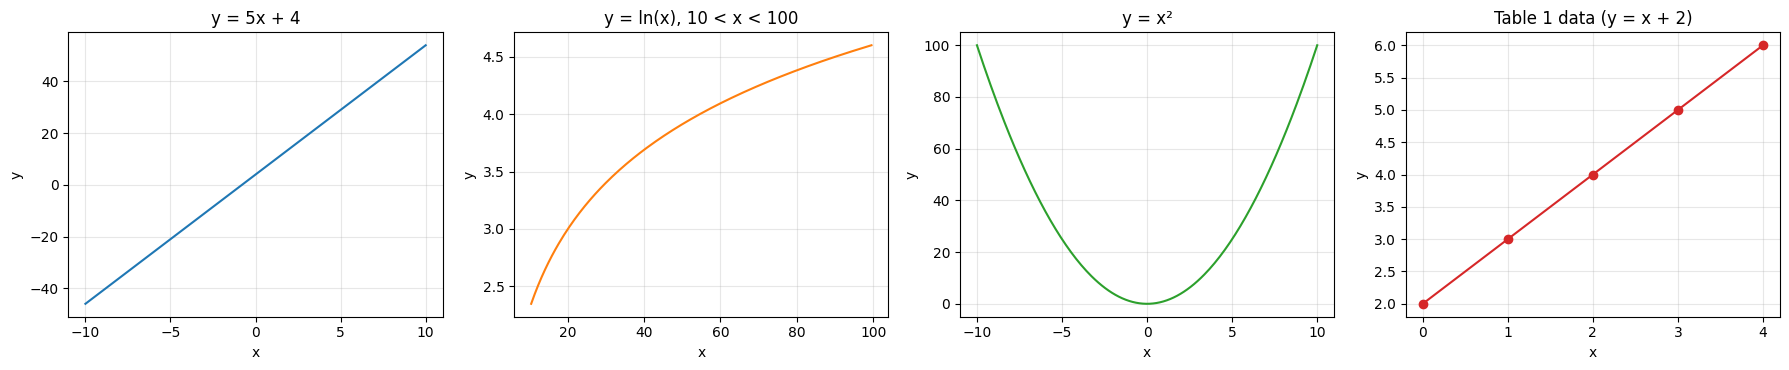

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
x = np.linspace(-10, 10, 200)
ax[0].plot(x, 5 * x + 4); ax[0].set_title('y = 5x + 4')
xl = np.linspace(10, 100, 200)[1:-1]          # open interval 10 < x < 100
ax[1].plot(xl, np.log(xl), color='tab:orange'); ax[1].set_title('y = ln(x), 10 < x < 100')
ax[2].plot(x, x ** 2, color='tab:green'); ax[2].set_title('y = x²')
tx, ty = [0, 1, 2, 3, 4], [2, 3, 4, 5, 6]
ax[3].plot(tx, ty, 'o-', color='tab:red'); ax[3].set_title('Table 1 data (y = x + 2)')
for a in ax:
    a.set_xlabel('x'); a.set_ylabel('y'); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Problem 5 — Evaluation metrics (scratch vs. sklearn)
The breast-cancer (Wisconsin) dataset: predict `diagnosis` (M = malignant = positive class, B = benign). A logistic-regression classifier is trained, then every metric is computed from the confusion matrix by hand and checked against sklearn.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

bc = pd.read_csv(os.path.join(DATA, 'data.csv')).drop(columns=['id', 'Unnamed: 32'])
X = bc.drop(columns='diagnosis').values
y = (bc['diagnosis'] == 'M').astype(int).values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=56)
sc = StandardScaler().fit(X_tr)
with np.errstate(all='ignore'):   # numpy 2 + macOS Accelerate emits spurious matmul warnings; results are unaffected
    clf = LogisticRegression(max_iter=1000).fit(sc.transform(X_tr), y_tr)
    y_pred = clf.predict(sc.transform(X_te))
print('test samples:', len(y_te), '| malignant:', y_te.sum())

test samples: 171 | malignant: 64


In [22]:
def confusion(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return tp, tn, fp, fn

def scratch_metrics(y_true, y_pred):
    tp, tn, fp, fn = confusion(y_true, y_pred)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)                       # = sensitivity = true positive rate
    specificity = tn / (tn + fp)                  # true negative rate
    return {
        'accuracy': (tp + tn) / len(y_true),
        'class acc (benign)': tn / (tn + fp),     # per-class accuracy = recall of that class
        'class acc (malignant)': tp / (tp + fn),
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall),
        'sensitivity': recall,
        'specificity': specificity,
    }

def sklearn_metrics(y_true, y_pred):
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, y_pred).ravel()
    per_class = metrics.recall_score(y_true, y_pred, average=None)
    return {
        'accuracy': metrics.accuracy_score(y_true, y_pred),
        'class acc (benign)': per_class[0],
        'class acc (malignant)': per_class[1],
        'precision': metrics.precision_score(y_true, y_pred),
        'recall': metrics.recall_score(y_true, y_pred),
        'f1': metrics.f1_score(y_true, y_pred),
        'sensitivity': metrics.recall_score(y_true, y_pred),
        'specificity': tn / (tn + fp),            # sklearn has no direct specificity function
    }

tp, tn, fp, fn = confusion(y_te, y_pred)
print(f'TP={tp}  TN={tn}  FP={fp}  FN={fn}\n')
table = pd.DataFrame({'scratch': scratch_metrics(y_te, y_pred), 'sklearn': sklearn_metrics(y_te, y_pred)})
table['match'] = np.isclose(table['scratch'], table['sklearn'])
table.round(4)

TP=63  TN=105  FP=2  FN=1



,scratch,sklearn,match
accuracy,0.9825,0.9825,True
class acc (benign),0.9813,0.9813,True
class acc (malignant),0.9844,0.9844,True
precision,0.9692,0.9692,True
recall,0.9844,0.9844,True
f1,0.9767,0.9767,True
sensitivity,0.9844,0.9844,True
specificity,0.9813,0.9813,True


**Average accuracy vs. class-wise accuracy:** overall accuracy weights each sample equally, so with 357 benign vs 212 malignant it leans towards the majority class. Class-wise accuracy (per-class recall) exposes how the model does on malignant cases specifically — which matters more here, since a false negative (missed cancer) is far costlier than a false positive. That is why recall/sensitivity is the metric to watch for this problem, with specificity showing the cost in false alarms.